# Análisis descriptivo – Food Delivery Times

Exploración de los datos: valores faltantes, valores atípicos, análisis univariado y bivariado.

## 1. Carga de datos

In [1]:
# Datos Kaggle
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("denkuznetz/food-delivery-time-prediction")

# print("Path to dataset files:", path)

# Lectura de datos
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"../data/Food_Delivery_Times.csv")
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [2]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    str    
 3   Traffic_Level           970 non-null    str    
 4   Time_of_Day             970 non-null    str    
 5   Vehicle_Type            1000 non-null   str    
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 70.4 KB


## 2. Valores faltantes

In [3]:
print(f"Datos nulos por columna:\n{df.isnull().sum()}\n")
print(f"Datos nulos por registro:\n{df.isnull().sum(axis=1).value_counts()}\n")
print(f"Registros con más de 1 dato nulo:\n{df[df.isnull().sum(axis=1) > 1]}")

Datos nulos por columna:
Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

Datos nulos por registro:
0    883
1    114
2      3
Name: count, dtype: int64

Registros con más de 1 dato nulo:
     Order_ID  Distance_km Weather Traffic_Level Time_of_Day Vehicle_Type  \
42        313         0.99     NaN        Medium     Evening         Bike   
353        70        19.74     NaN           Low         NaN          Car   
379       814        18.46   Clear           NaN         NaN      Scooter   

     Preparation_Time_min  Courier_Experience_yrs  Delivery_Time_min  
42                     15                     NaN                 32  
353                    21                     7.0                 71  
379                    29                     1.0               

### Comportamiento de registros con datos faltantes en las demás variables

In [4]:
numericas = ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs", "Delivery_Time_min"]
categoricas = ["Weather", "Traffic_Level", "Time_of_Day", "Vehicle_Type"]

df["nulos_por_fila"] = df.isnull().sum(axis=1)
df["tiene_nulos"] = df["nulos_por_fila"].gt(0).map({True: "Con faltantes", False: "Completa"})


In [5]:
# Variables numericas
print(f"Estadísticas descriptivas:\n{df[numericas].describe().T}\n")
print(f"Media por grupo de nulos:\n{df.groupby('tiene_nulos')[numericas].mean().T}")

Estadísticas descriptivas:
                         count       mean        std   min     25%    50%  \
Distance_km             1000.0  10.059970   5.696656  0.59   5.105  10.19   
Preparation_Time_min    1000.0  16.982000   7.204553  5.00  11.000  17.00   
Courier_Experience_yrs   970.0   4.579381   2.914394  0.00   2.000   5.00   
Delivery_Time_min       1000.0  56.732000  22.070915  8.00  41.000  55.50   

                            75%     max  
Distance_km             15.0175   19.99  
Preparation_Time_min    23.0000   29.00  
Courier_Experience_yrs   7.0000    9.00  
Delivery_Time_min       71.0000  153.00  

Media por grupo de nulos:
tiene_nulos              Completa  Con faltantes
Distance_km             10.051586      10.123248
Preparation_Time_min    17.019253      16.700855
Courier_Experience_yrs   4.639864       3.965517
Delivery_Time_min       56.425821      59.042735


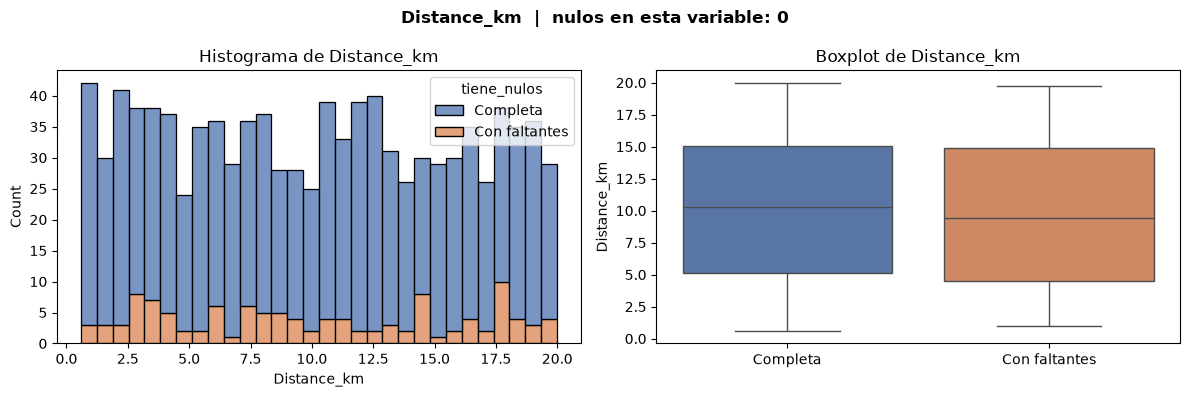

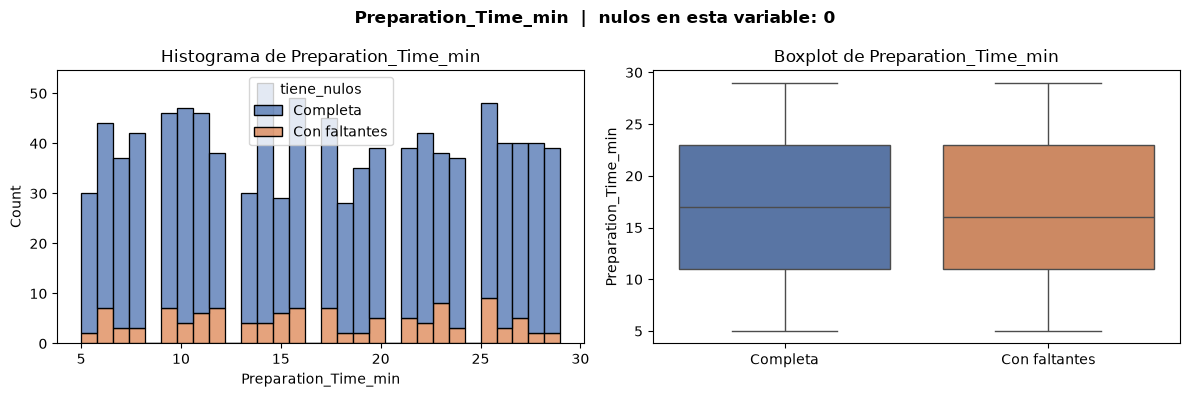

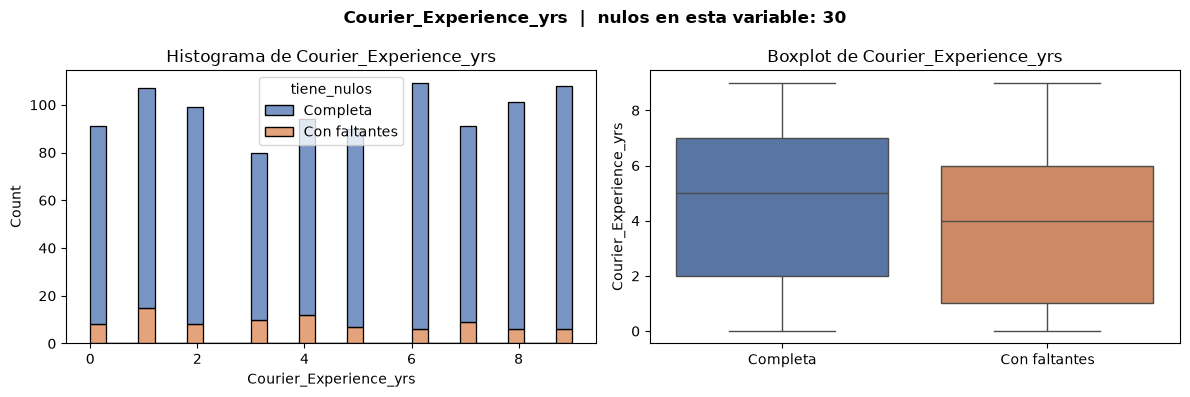

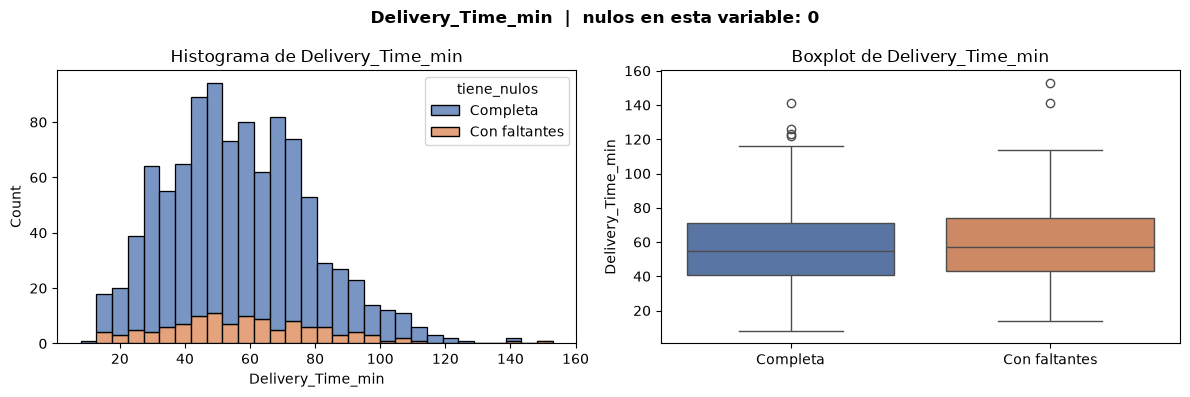

In [6]:
# Histograma y boxplot de variables numericas por grupo de registros con nulos y sin nulos
palette = {"Completa": "#4C72B0", "Con faltantes": "#DD8452"}

for col in numericas:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(data=df, x=col, hue="tiene_nulos", multiple="stack",
                 bins=30, palette=palette, ax=axes[0])
    axes[0].set_title(f"Histograma de {col}")

    sns.boxplot(data=df, x="tiene_nulos", y=col, hue="tiene_nulos",
                palette=palette, legend=False, ax=axes[1])
    axes[1].set_title(f"Boxplot de {col}")
    axes[1].set_xlabel("")

    n_nulos = df[col].isnull().sum()
    fig.suptitle(f"{col}  |  nulos en esta variable: {n_nulos}", fontweight="bold")
    plt.tight_layout()
    plt.show()

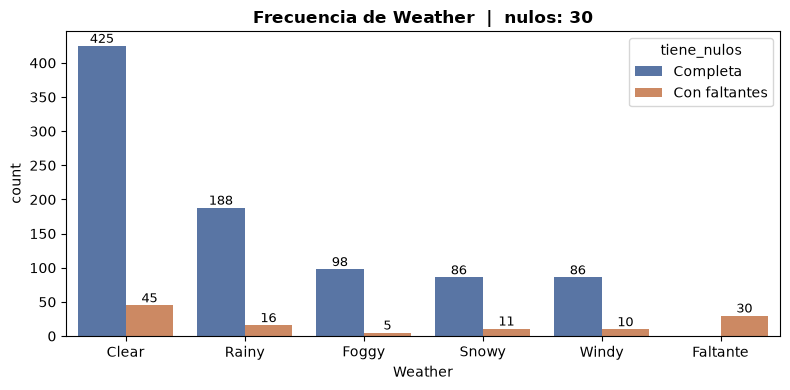


=== Weather (proporciones, incluye faltantes) ===
Weather
Clear       0.470
Rainy       0.204
Foggy       0.103
Snowy       0.097
Windy       0.096
Faltante    0.030
Name: proportion, dtype: float64


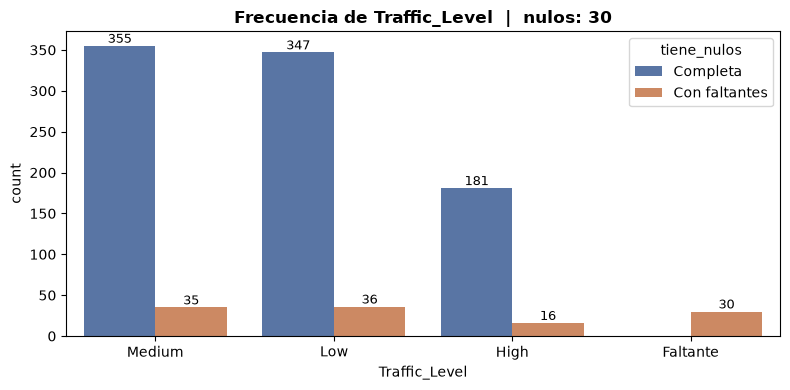


=== Traffic_Level (proporciones, incluye faltantes) ===
Traffic_Level
Medium      0.390
Low         0.383
High        0.197
Faltante    0.030
Name: proportion, dtype: float64


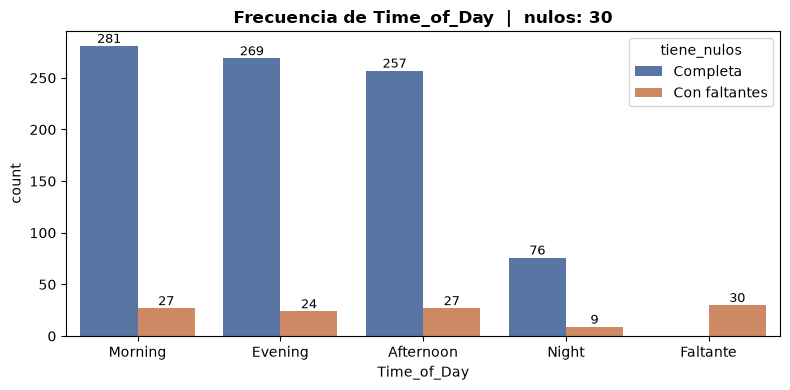


=== Time_of_Day (proporciones, incluye faltantes) ===
Time_of_Day
Morning      0.308
Evening      0.293
Afternoon    0.284
Night        0.085
Faltante     0.030
Name: proportion, dtype: float64


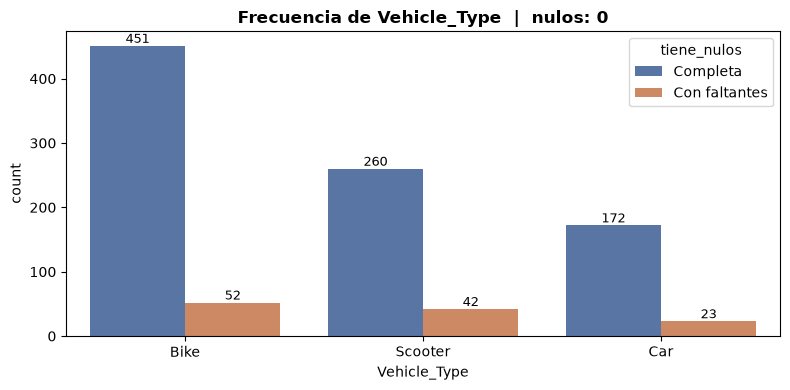


=== Vehicle_Type (proporciones, incluye faltantes) ===
Vehicle_Type
Bike       0.503
Scooter    0.302
Car        0.195
Name: proportion, dtype: float64


In [7]:
# Variables categoricas con grupos de registros con nulos y sin nulos
for col in categoricas:
    tmp = df[[col, "tiene_nulos"]].copy()
    tmp[col] = tmp[col].fillna("Faltante")

    fig, ax = plt.subplots(figsize=(8, 4))
    orden = tmp[col].value_counts().index
    sns.countplot(data=tmp, x=col, hue="tiene_nulos", order=orden,
                  palette=palette, ax=ax)
    ax.set_title(f"Frecuencia de {col}  |  nulos: {df[col].isnull().sum()}", fontweight="bold")

    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(int(h), (p.get_x() + p.get_width() / 2, h),
                        ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    plt.show()

    print(f"\n=== {col} (proporciones, incluye faltantes) ===")
    print(tmp[col].value_counts(normalize=True).round(3))

## 3. Valores atípicos

In [8]:
# 1. Atípicos en numéricas: métodos IQR y Z-score
resumen = []

for col in numericas:
    serie = df[col].dropna()

    # IQR
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    lim_inf_ext, lim_sup_ext = q1 - 3 * iqr, q3 + 3 * iqr
    df[f"{col}_atipico_IQR"] = (df[col] < lim_inf) | (df[col] > lim_sup)

    # Z-score (|z| > 3)
    z = (df[col] - serie.mean()) / serie.std()
    df[f"{col}_atipico_Z"] = z.abs() > 3

    resumen.append({
        "Variable": col,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "Lim_inf_IQR": round(lim_inf, 2),
        "Lim_sup_IQR": round(lim_sup, 2),
        "Lim_inf_ext": round(lim_inf_ext, 2),
        "Lim_sup_ext": round(lim_sup_ext, 2),
        "Min": serie.min(),
        "Max": serie.max(),
        "Atipicos_IQR": int(df[f"{col}_atipico_IQR"].sum()),
        "%_IQR": round(df[f"{col}_atipico_IQR"].mean() * 100, 2),
        "Atipicos_Z": int(df[f"{col}_atipico_Z"].sum()),
    })

resumen = pd.DataFrame(resumen)
print("=== Resumen de atípicos (numéricas) ===")
print(resumen.to_string(index=False))

=== Resumen de atípicos (numéricas) ===
              Variable    Q1    Q3  Lim_inf_IQR  Lim_sup_IQR  Lim_inf_ext  Lim_sup_ext  Min    Max  Atipicos_IQR  %_IQR  Atipicos_Z
           Distance_km  5.11 15.02        -9.76        29.89       -24.63        44.75 0.59  19.99             0    0.0           0
  Preparation_Time_min 11.00 23.00        -7.00        41.00       -25.00        59.00 5.00  29.00             0    0.0           0
Courier_Experience_yrs  2.00  7.00        -5.50        14.50       -13.00        22.00 0.00   9.00             0    0.0           0
     Delivery_Time_min 41.00 71.00        -4.00       116.00       -49.00       161.00 8.00 153.00             6    0.6           5


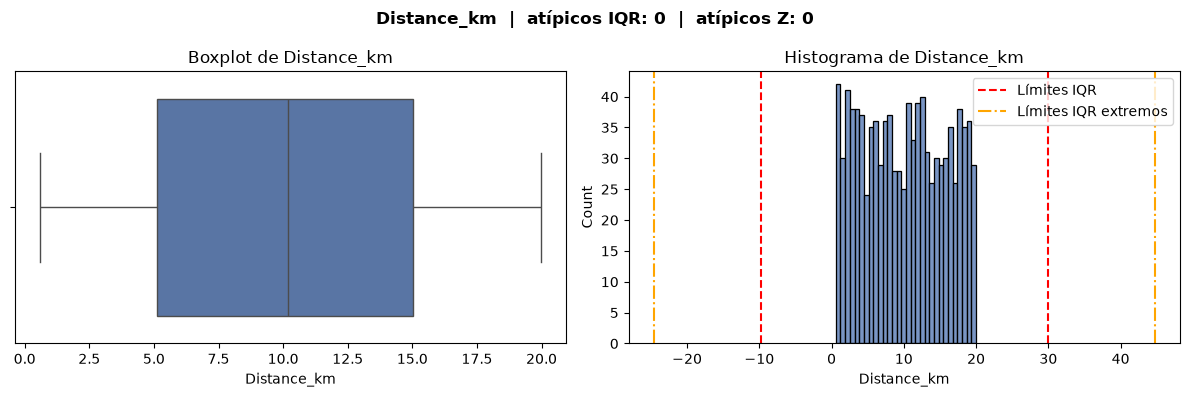

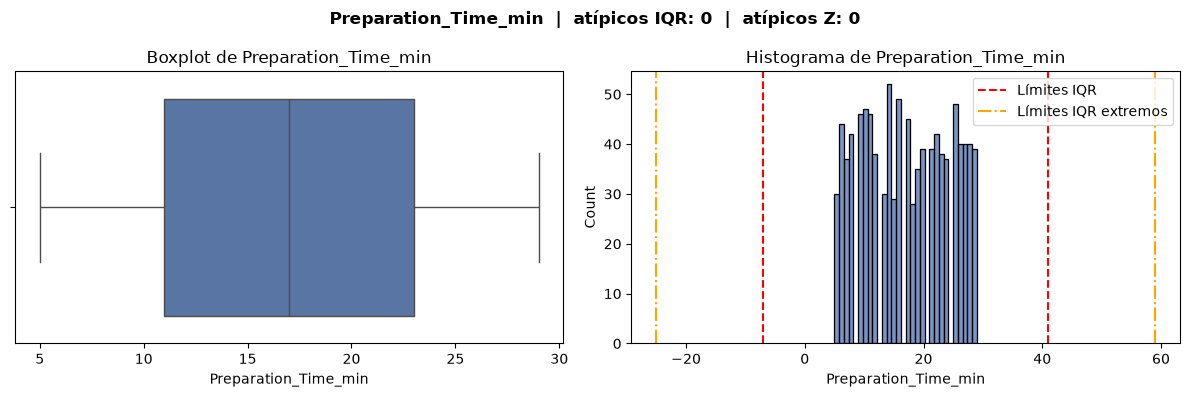

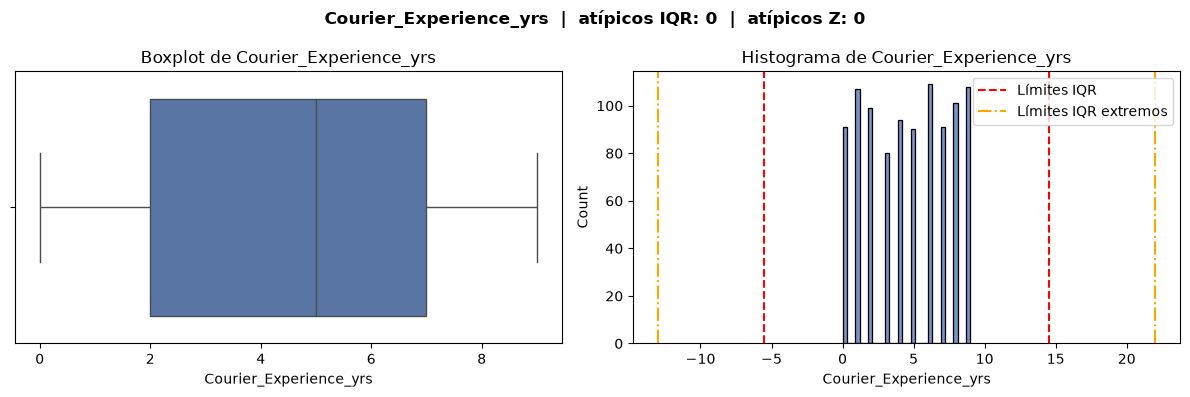

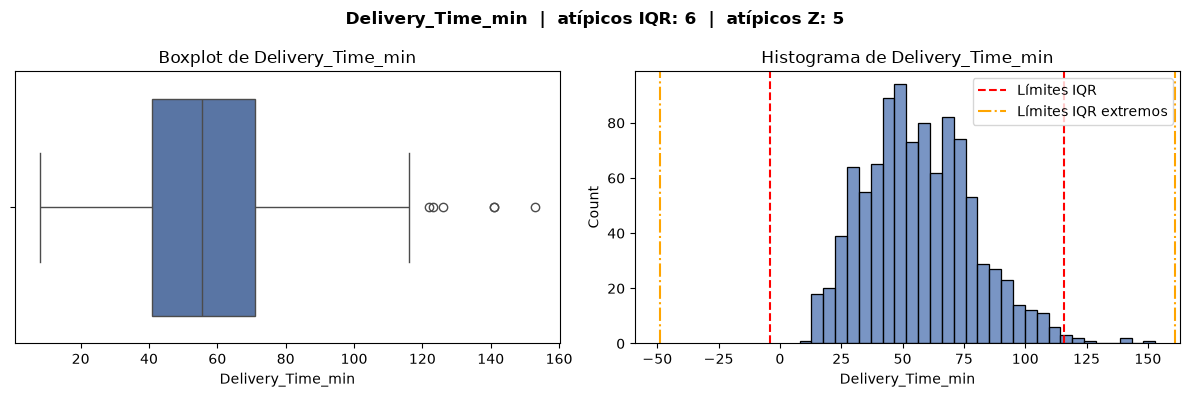

In [9]:
# 2. Gráficas: boxplot + histograma con límites IQR
for col in numericas:
    fila = resumen[resumen["Variable"] == col].iloc[0]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.boxplot(x=df[col], color="#4C72B0", ax=axes[0])
    axes[0].set_title(f"Boxplot de {col}")

    sns.histplot(df[col], bins=30, color="#4C72B0", ax=axes[1])
    axes[1].axvline(fila["Lim_inf_IQR"], color="red", linestyle="--", label="Límites IQR")
    axes[1].axvline(fila["Lim_sup_IQR"], color="red", linestyle="--")
    axes[1].axvline(fila["Lim_inf_ext"], color="orange", linestyle="-.", label="Límites IQR extremos")
    axes[1].axvline(fila["Lim_sup_ext"], color="orange", linestyle="-.")
    axes[1].legend()
    axes[1].set_title(f"Histograma de {col}")

    fig.suptitle(f"{col}  |  atípicos IQR: {fila['Atipicos_IQR']}  |  atípicos Z: {fila['Atipicos_Z']}",
                 fontweight="bold")
    plt.tight_layout()
    plt.show()

In [10]:
# 3. Ver los registros atípicos de cada variable
for col in numericas:
    atipicos = df[df[f"{col}_atipico_IQR"]]
    if len(atipicos) > 0:
        print(f"\n=== Registros atípicos en {col} ({len(atipicos)}) ===")
        print(atipicos[["Order_ID", col]].sort_values(col, ascending=False).to_string(index=False))


=== Registros atípicos en Delivery_Time_min (6) ===
 Order_ID  Delivery_Time_min
      814                153
      446                141
      394                141
      385                126
      948                123
      428                122


In [11]:
# 4. Filas atípicas en más de una variable
cols_flag = [f"{c}_atipico_IQR" for c in numericas]
df["n_atipicos"] = df[cols_flag].sum(axis=1)
print("\n=== Filas según cantidad de variables atípicas ===")
print(df["n_atipicos"].value_counts().sort_index())


=== Filas según cantidad de variables atípicas ===
n_atipicos
0    994
1      6
Name: count, dtype: int64


### Atípicos vs. datos faltantes

In [13]:
# Marca de faltantes por fila
cols_originales = numericas + categoricas
df["nulos_por_fila"] = df[cols_originales].isnull().sum(axis=1)
df["tiene_nulos"] = df["nulos_por_fila"] > 0
df["es_atipico"] = df["n_atipicos"] > 0

In [14]:
# 1. Tabla: atípico vs. faltante
print("=== Atípicos vs. faltantes (cantidad de filas) ===")
tabla = pd.crosstab(df["es_atipico"], df["tiene_nulos"],
                    rownames=["Es atípico"], colnames=["Tiene faltantes"], margins=True)
print(tabla)

=== Atípicos vs. faltantes (cantidad de filas) ===
Tiene faltantes  False  True   All
Es atípico                        
False              879   115   994
True                 4     2     6
All                883   117  1000


In [15]:
# 2. Por variable: cuántos atípicos tienen algún faltante
detalle = []
for col in numericas:
    atip = df[df[f"{col}_atipico_IQR"]]
    detalle.append({
        "Variable atípica": col,
        "N° atípicos": len(atip),
        "Con algún faltante": int(atip["tiene_nulos"].sum()),
        "%": round(atip["tiene_nulos"].mean() * 100, 2) if len(atip) > 0 else 0,
    })
print("\n=== Atípicos con faltantes por variable ===")
print(pd.DataFrame(detalle).to_string(index=False))


=== Atípicos con faltantes por variable ===
      Variable atípica  N° atípicos  Con algún faltante     %
           Distance_km            0                   0  0.00
  Preparation_Time_min            0                   0  0.00
Courier_Experience_yrs            0                   0  0.00
     Delivery_Time_min            6                   2 33.33


In [16]:
# 3. En qué columnas están los faltantes de los registros atípicos
atipicos = df[df["es_atipico"]]
print("\n=== Faltantes por columna dentro de los registros atípicos ===")
print(atipicos[cols_originales].isnull().sum())



=== Faltantes por columna dentro de los registros atípicos ===
Distance_km               0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
Weather                   0
Traffic_Level             1
Time_of_Day               2
Vehicle_Type              0
dtype: int64


In [17]:
# 4. Listado de registros atípicos que tienen faltantes
atip_con_nulos = atipicos[atipicos["tiene_nulos"]].copy()
atip_con_nulos["variables_atipicas"] = atip_con_nulos.apply(
    lambda r: ", ".join(c for c in numericas if r[f"{c}_atipico_IQR"]), axis=1)
atip_con_nulos["columnas_faltantes"] = atip_con_nulos[cols_originales].isnull().apply(
    lambda r: ", ".join(r.index[r]), axis=1)

print(f"\n=== Registros atípicos con faltantes ({len(atip_con_nulos)}) ===")
print(atip_con_nulos[["Order_ID", "variables_atipicas", "columnas_faltantes"] + numericas]
      .to_string(index=False))


=== Registros atípicos con faltantes (2) ===
 Order_ID variables_atipicas         columnas_faltantes  Distance_km  Preparation_Time_min  Courier_Experience_yrs  Delivery_Time_min
      814  Delivery_Time_min Traffic_Level, Time_of_Day        18.46                    29                     1.0                153
      394  Delivery_Time_min                Time_of_Day        15.64                    20                     4.0                141


### Categorías poco frecuentes

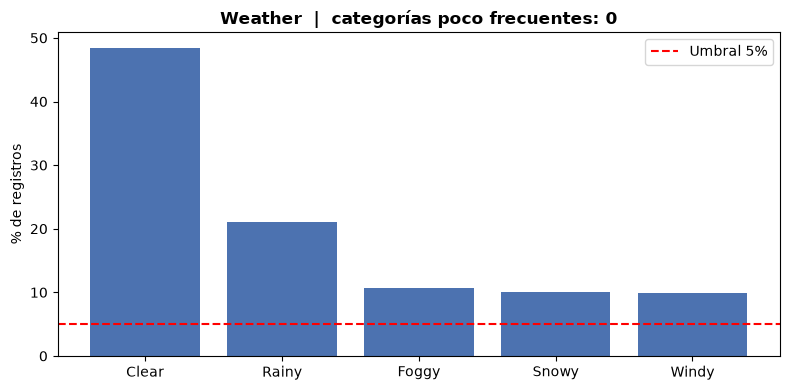


=== Weather ===
Weather
Clear    48.45 %
Rainy    21.03 %
Foggy    10.62 %
Snowy     10.0 %
Windy      9.9 %
Name: proportion, dtype: str


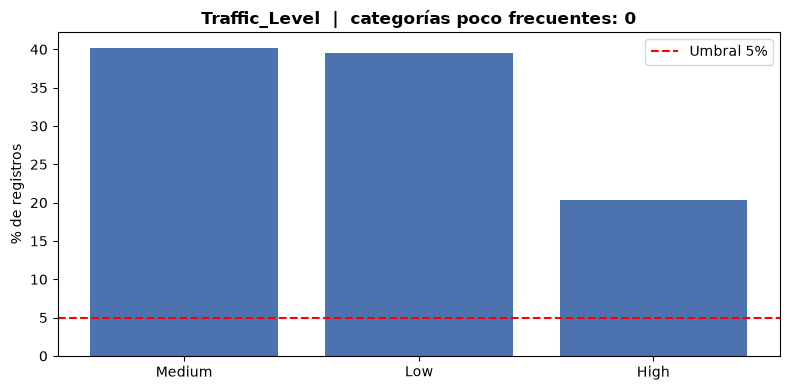


=== Traffic_Level ===
Traffic_Level
Medium    40.21 %
Low       39.48 %
High      20.31 %
Name: proportion, dtype: str


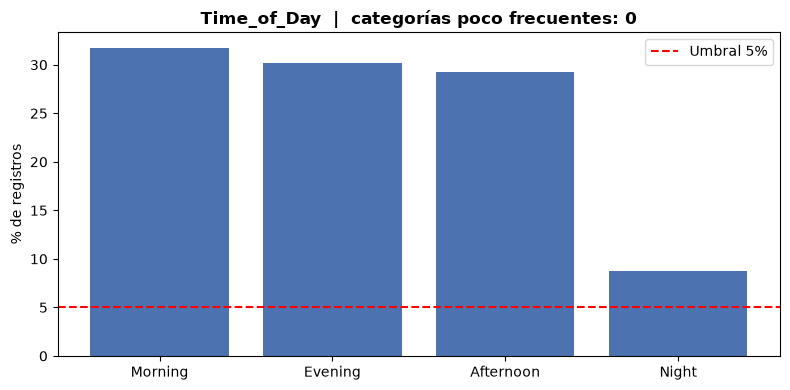


=== Time_of_Day ===
Time_of_Day
Morning      31.75 %
Evening      30.21 %
Afternoon    29.28 %
Night         8.76 %
Name: proportion, dtype: str


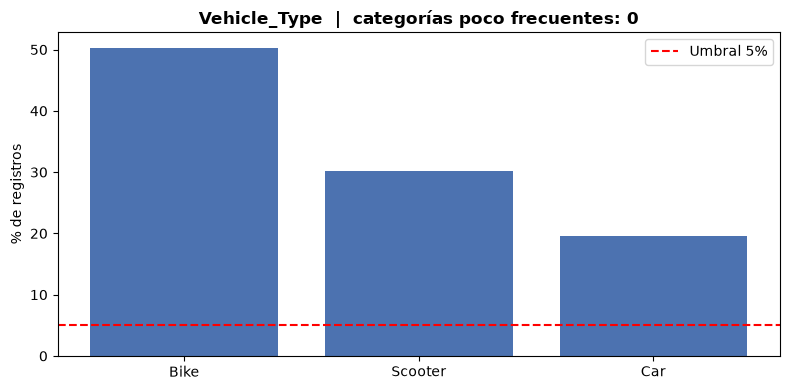


=== Vehicle_Type ===
Vehicle_Type
Bike       50.3 %
Scooter    30.2 %
Car        19.5 %
Name: proportion, dtype: str


In [19]:
# 5. Categóricas: categorías poco frecuentes (< 5%)
umbral = 0.05
for col in categoricas:
    frec = df[col].value_counts(normalize=True)
    raras = frec[frec < umbral]

    fig, ax = plt.subplots(figsize=(8, 4))
    colores = ["#DD8452" if f < umbral else "#4C72B0" for f in frec]
    ax.bar(frec.index, frec.values * 100, color=colores)
    ax.axhline(umbral * 100, color="red", linestyle="--", label=f"Umbral {umbral:.0%}")
    ax.set_ylabel("% de registros")
    ax.set_title(f"{col}  |  categorías poco frecuentes: {len(raras)}", fontweight="bold")
    ax.legend()
    plt.tight_layout()
    plt.show()

    print(f"\n=== {col} ===")
    print((frec * 100).round(2).astype(str) + " %")
    if len(raras) > 0:
        print(f"-> Categorías raras: {list(raras.index)}")

## 4. Qué hacer con los atípicos y datos faltantes

In [20]:
import scipy.stats as st
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression

In [21]:
target = "Delivery_Time_min"
numericas = ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs"]
categoricas = ["Weather", "Traffic_Level", "Time_of_Day", "Vehicle_Type"]
cols_con_nulos = [c for c in numericas + categoricas if df[c].isnull().any()]

# 1. ¿Cuánto perdería si elimino filas?
filas_nulas = df[numericas + categoricas].isnull().any(axis=1)
print(f"Filas con algún faltante: {filas_nulas.sum()} ({filas_nulas.mean():.1%})")
print(f"Filas que quedarían al eliminar: {(~filas_nulas).sum()}")

Filas con algún faltante: 117 (11.7%)
Filas que quedarían al eliminar: 883


In [ ]:
# 2. Los faltantes son aleatorios? -- Prueba de comparación de grupos mannwhitneyu (numéricas) ordena valores de los dos grupos y observa sus concentraciones y chi2 (categóricas), compara proporciones entre niveles de la variable categórica.
# G1: registro sin faltante, G2: registro con faltante. p < 0.05 -> NO parece aleatorio
print("\n=== Prueba de aleatoriedad de los faltantes (p-valores) ===")
resultados = []
for col_nula in cols_con_nulos:
    es_nulo = df[col_nula].isnull()
    for otra in numericas + [target] + categoricas:
        if otra == col_nula:
            continue
        if otra in categoricas:
            tabla = pd.crosstab(es_nulo, df[otra])
            p = st.chi2_contingency(tabla)[1]
            prueba = "Chi2"
        else:
            a = df.loc[es_nulo, otra].dropna() # Datos donde falta un valor en col_nula
            b = df.loc[~es_nulo, otra].dropna() # Datos donde NO falta un valor en col_nula
            p = st.mannwhitneyu(a, b).pvalue
            prueba = "Mann-Whitney"
        resultados.append({"Columna con nulos": col_nula, "Comparada con": otra,
                           "Prueba": prueba, "p_valor": round(p, 4),
                           "Aleatorio?": "Sí" if p >= 0.05 else "NO"})
res = pd.DataFrame(resultados)
print(res.to_string(index=False))


=== Prueba de aleatoriedad de los faltantes (p-valores) ===
     Columna con nulos          Comparada con       Prueba  p_valor Aleatorio?
Courier_Experience_yrs            Distance_km Mann-Whitney   0.8248         Sí
Courier_Experience_yrs   Preparation_Time_min Mann-Whitney   0.5142         Sí
Courier_Experience_yrs      Delivery_Time_min Mann-Whitney   0.9200         Sí
Courier_Experience_yrs                Weather         Chi2   0.5119         Sí
Courier_Experience_yrs          Traffic_Level         Chi2   0.9981         Sí
Courier_Experience_yrs            Time_of_Day         Chi2   0.6170         Sí
Courier_Experience_yrs           Vehicle_Type         Chi2   0.2989         Sí
               Weather            Distance_km Mann-Whitney   0.2319         Sí
               Weather   Preparation_Time_min Mann-Whitney   0.2874         Sí
               Weather Courier_Experience_yrs Mann-Whitney   0.2244         Sí
               Weather      Delivery_Time_min Mann-Whitney   0.5172   

In [23]:
# 3. ¿El faltante cambia el tiempo de entrega?
print("\n=== Delivery_Time medio: con vs. sin faltante ===")
for col in cols_con_nulos:
    m = df.groupby(df[col].isnull())[target].mean()
    print(f"{col:25s} sin nulo={m[False]:.1f}  con nulo={m[True]:.1f}")


=== Delivery_Time medio: con vs. sin faltante ===
Courier_Experience_yrs    sin nulo=56.7  con nulo=56.4
Weather                   sin nulo=56.8  con nulo=54.2
Traffic_Level             sin nulo=56.6  con nulo=62.1
Time_of_Day               sin nulo=56.4  con nulo=66.2


In [24]:
# 4. Comparar estrategias de imputación con validación cruzada
def evaluar(X, y, preprocesador, nombre):
    pipe = Pipeline([("prep", preprocesador), ("modelo", LinearRegression())])
    cv = KFold(n_splits=5, shuffle=True, random_state=17)
    mae = -cross_val_score(pipe, X, y, cv=cv, scoring="neg_mean_absolute_error")
    return {"Estrategia": nombre, "Filas": len(X), "MAE": round(mae.mean(), 3),
            "MAE_std": round(mae.std(), 3)}

X, y = df[numericas + categoricas], df[target]
ohe = OneHotEncoder(handle_unknown="ignore")

estrategias = []


In [25]:
# a) Eliminar filas
d = df.dropna(subset=numericas + categoricas)
prep = ColumnTransformer([("num", StandardScaler(), numericas),
                          ("cat", ohe, categoricas)])
estrategias.append(evaluar(d[numericas + categoricas], d[target], prep, "Eliminar filas"))

In [26]:
# b) Mediana + moda
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), numericas),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", ohe)]), categoricas)])
estrategias.append(evaluar(X, y, prep, "Mediana + Moda"))


In [27]:
# c) KNN para numéricas + moda para categóricas
prep = ColumnTransformer([
    ("num", Pipeline([("sc", StandardScaler()), ("imp", KNNImputer(n_neighbors=5))]), numericas),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", ohe)]), categoricas)])
estrategias.append(evaluar(X, y, prep, "KNN + Moda"))

print("\n=== Comparación de estrategias (menor MAE = mejor) ===")
print(pd.DataFrame(estrategias).sort_values("MAE").to_string(index=False))


=== Comparación de estrategias (menor MAE = mejor) ===
    Estrategia  Filas   MAE  MAE_std
Eliminar filas    883 6.341    0.307
Mediana + Moda   1000 6.631    0.887
    KNN + Moda   1000 6.631    0.877


**Decisión:** imputar datos con mediana (numéricas) y moda (categóricas).

## 5. Análisis bivariado

In [28]:
from scipy import stats
from itertools import combinations
import numpy as np

target = "Delivery_Time_min"
numericas = ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs"]
categoricas = ["Weather", "Traffic_Level", "Time_of_Day", "Vehicle_Type"]

# Funciones de asociación
def cramers_v(x, y):
    """Asociación entre dos categóricas (0 = nada, 1 = total)."""
    tabla = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(tabla)[0]
    n = tabla.values.sum()
    r, k = tabla.shape
    # corrección de sesgo (Bergsma)
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c = r - (r - 1) ** 2 / (n - 1)
    k_c = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-10, min(k_c - 1, r_c - 1)))

def eta(cat, num):
    """Razón de correlación: asociación categórica -> numérica (0 a 1)."""
    d = pd.DataFrame({"c": cat, "n": num}).dropna()
    media = d["n"].mean()
    ss_between = sum(len(g) * (g.mean() - media) ** 2 for _, g in d.groupby("c")["n"])
    ss_total = ((d["n"] - media) ** 2).sum()
    return np.sqrt(ss_between / ss_total)

### Delivery_Time vs. cada variable

=== Delivery_Time vs. numéricas ===
Distance_km               Pearson=0.781 (p=0.0000)  Spearman=0.817 (p=0.0000)
Preparation_Time_min      Pearson=0.307 (p=0.0000)  Spearman=0.306 (p=0.0000)
Courier_Experience_yrs    Pearson=-0.090 (p=0.0048)  Spearman=-0.087 (p=0.0069)


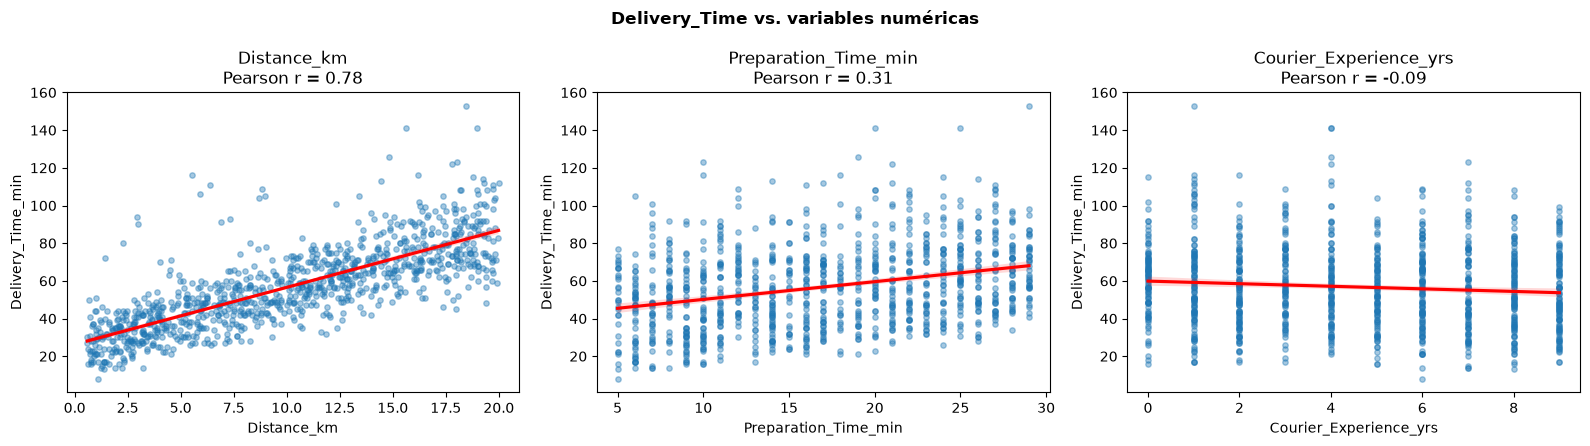

In [30]:
# Numéricas vs. Delivery_Time
print("=== Delivery_Time vs. numéricas ===")
fig, axes = plt.subplots(1, len(numericas), figsize=(16, 4.5))
for ax, col in zip(axes, numericas):
    d = df[[col, target]].dropna()
    pear, p_pear = stats.pearsonr(d[col], d[target])
    spear, p_spear = stats.spearmanr(d[col], d[target])
    print(f"{col:25s} Pearson={pear:.3f} (p={p_pear:.4f})  Spearman={spear:.3f} (p={p_spear:.4f})")

    sns.regplot(data=d, x=col, y=target, ax=ax,
                scatter_kws={"alpha": 0.4, "s": 15}, line_kws={"color": "red"})
    ax.set_title(f"{col}\nPearson r = {pear:.2f}")
plt.suptitle("Delivery_Time vs. variables numéricas", fontweight="bold")
plt.tight_layout()
plt.show()


=== Delivery_Time vs. categóricas ===

Weather: ANOVA p=0.0000 | Kruskal-Wallis p=0.0000 | eta=0.204
         count   mean  median    std
Weather                             
Clear      470  53.08    52.0  21.27
Windy       96  55.46    55.0  21.78
Rainy      204  59.79    57.5  22.82
Foggy      103  59.47    59.0  20.86
Snowy       97  67.11    66.0  21.29

Traffic_Level: ANOVA p=0.0000 | Kruskal-Wallis p=0.0000 | eta=0.200
               count   mean  median    std
Traffic_Level                             
Low              383  52.89    51.0  21.68
Medium           390  56.02    53.5  21.19
High             197  64.81    65.0  21.87

Time_of_Day: ANOVA p=0.7765 | Kruskal-Wallis p=0.8111 | eta=0.034
             count   mean  median    std
Time_of_Day                             
Morning        308  56.12    56.0  21.54
Afternoon      284  56.08    56.0  21.09
Evening        293  57.48    56.0  22.18
Night           85  55.21    52.0  21.43

Vehicle_Type: ANOVA p=0.5549 | Kruskal-Wa

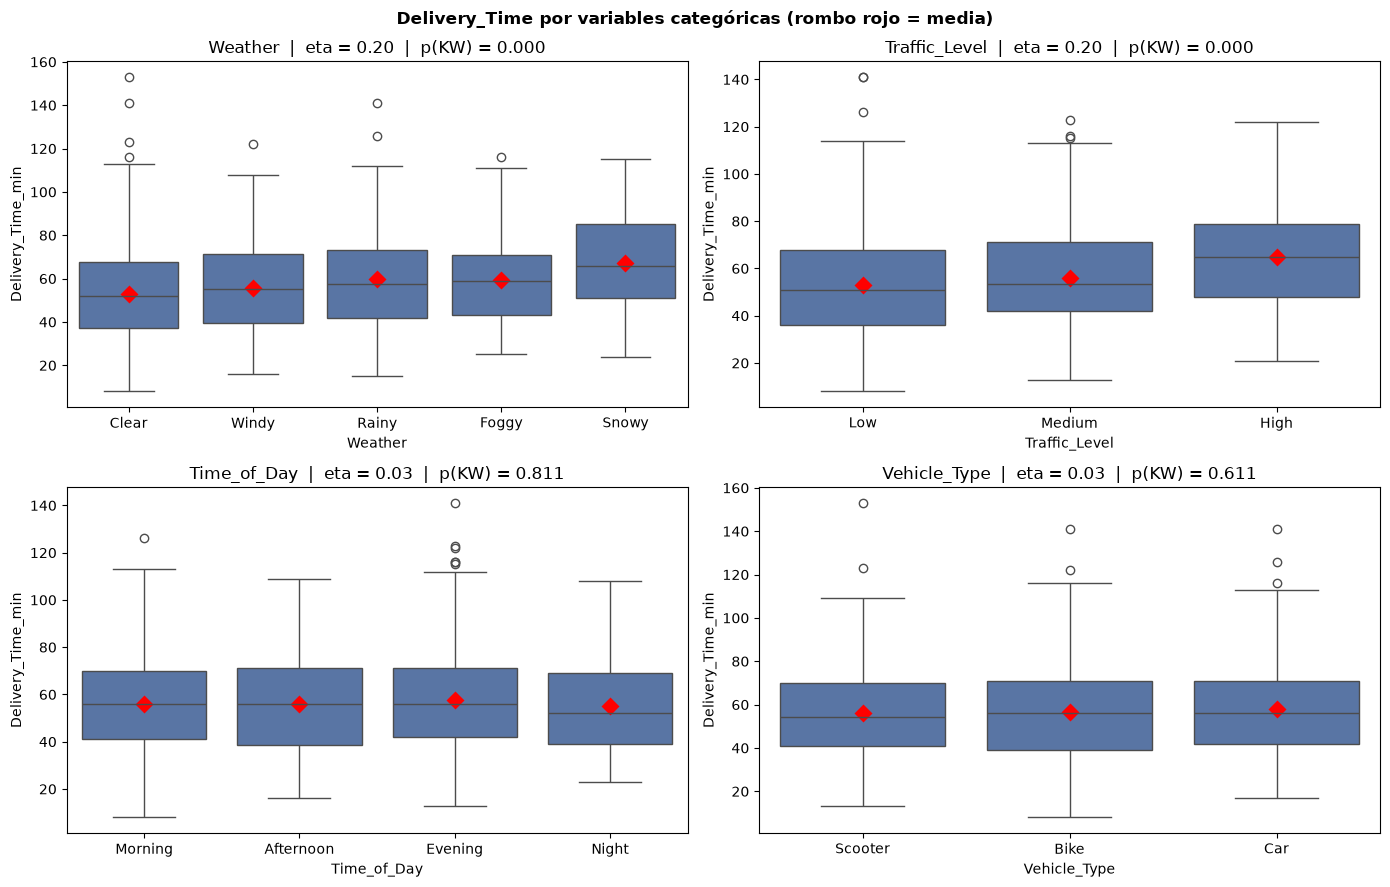

In [31]:
# Categóricas vs. Delivery_Time
orden_cat = {
    "Traffic_Level": ["Low", "Medium", "High"],
    "Time_of_Day": ["Morning", "Afternoon", "Evening", "Night"],
}

print("\n=== Delivery_Time vs. categóricas ===")
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, categoricas):
    d = df[[col, target]].dropna()
    orden = [o for o in orden_cat.get(col, []) if o in d[col].unique()] or \
            d.groupby(col)[target].median().sort_values().index.tolist()

    grupos = [g[target].values for _, g in d.groupby(col)]
    f_stat, p_anova = stats.f_oneway(*grupos)
    h_stat, p_kw = stats.kruskal(*grupos)
    e = eta(d[col], d[target])

    print(f"\n{col}: ANOVA p={p_anova:.4f} | Kruskal-Wallis p={p_kw:.4f} | eta={e:.3f}")
    print(d.groupby(col)[target].agg(["count", "mean", "median", "std"]).round(2).loc[orden])

    sns.boxplot(data=d, x=col, y=target, order=orden, ax=ax, color="#4C72B0")
    sns.pointplot(data=d, x=col, y=target, order=orden, ax=ax,
                  color="red", errorbar=None, markers="D", linestyles="")
    ax.set_title(f"{col}  |  eta = {e:.2f}  |  p(KW) = {p_kw:.3f}")
plt.suptitle("Delivery_Time por variables categóricas (rombo rojo = media)", fontweight="bold")
plt.tight_layout()
plt.show()

### Relaciones entre las demás variables

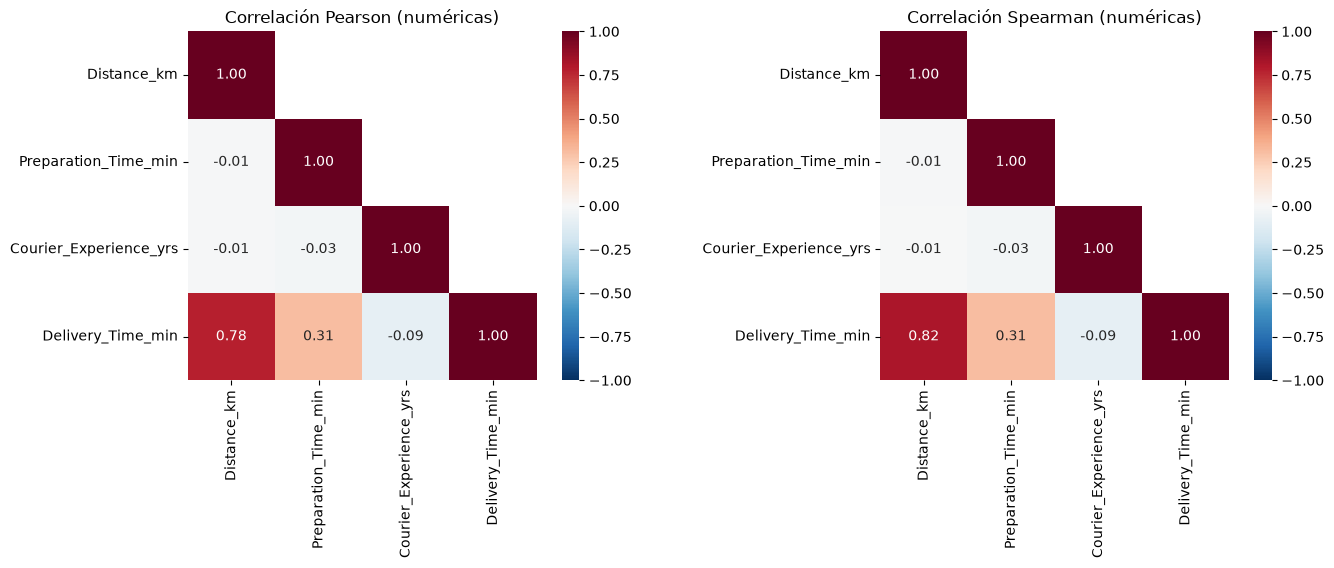

In [32]:
# Matriz de correlación numérica (Pearson y Spearman)
num_all = numericas + [target]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    corr = df[num_all].corr(method=metodo)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
                vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title(f"Correlación {metodo.capitalize()} (numéricas)")
plt.tight_layout()
plt.show()

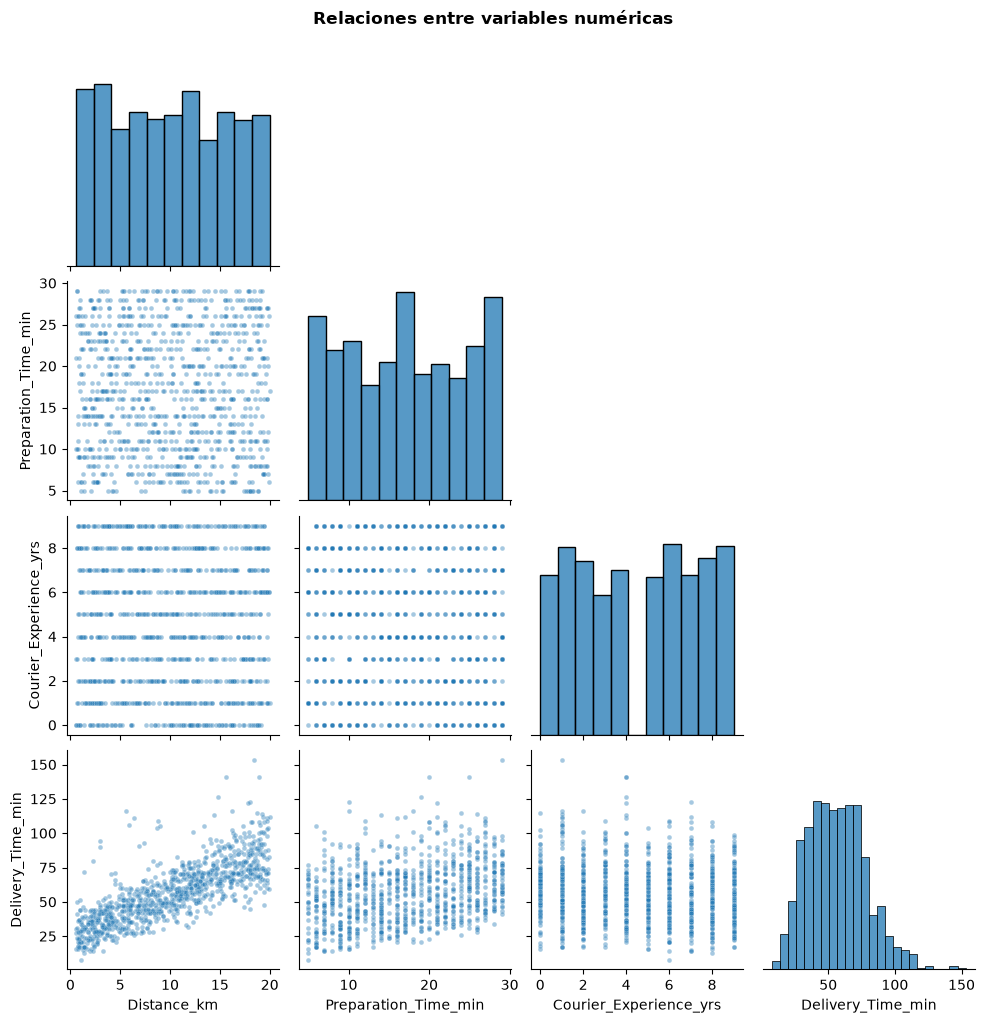

In [33]:
# Pairplot de numéricas
sns.pairplot(df[num_all].dropna(), corner=True, plot_kws={"alpha": 0.4, "s": 12})
plt.suptitle("Relaciones entre variables numéricas", y=1.02, fontweight="bold")
plt.show()


=== Asociación entre categóricas (Chi-cuadrado) ===
Weather         vs Traffic_Level   V de Cramér=0.050  p=0.1211
Weather         vs Time_of_Day     V de Cramér=0.000  p=0.7977
Weather         vs Vehicle_Type    V de Cramér=0.039  p=0.2062
Traffic_Level   vs Time_of_Day     V de Cramér=0.000  p=0.4969
Traffic_Level   vs Vehicle_Type    V de Cramér=0.032  p=0.1982
Time_of_Day     vs Vehicle_Type    V de Cramér=0.057  p=0.0563


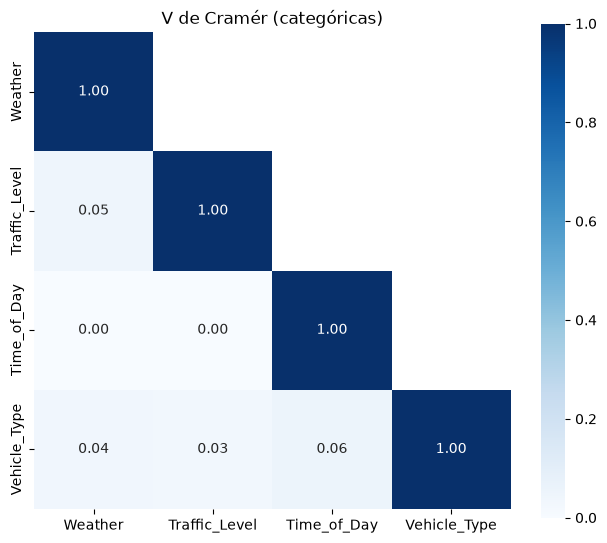

In [34]:
# Matriz de asociación entre categóricas (V de Cramér)
cramer = pd.DataFrame(np.eye(len(categoricas)), index=categoricas, columns=categoricas)
print("\n=== Asociación entre categóricas (Chi-cuadrado) ===")
for a, b in combinations(categoricas, 2):
    d = df[[a, b]].dropna()
    v = cramers_v(d[a], d[b])
    p = stats.chi2_contingency(pd.crosstab(d[a], d[b]))[1]
    cramer.loc[a, b] = cramer.loc[b, a] = v
    print(f"{a:15s} vs {b:15s} V de Cramér={v:.3f}  p={p:.4f}")

plt.figure(figsize=(6.5, 5.5))
mask = np.triu(np.ones_like(cramer, dtype=bool), k=1)
sns.heatmap(cramer, mask=mask, annot=True, fmt=".2f", cmap="Blues",
            vmin=0, vmax=1, square=True)
plt.title("V de Cramér (categóricas)")
plt.tight_layout()
plt.show()

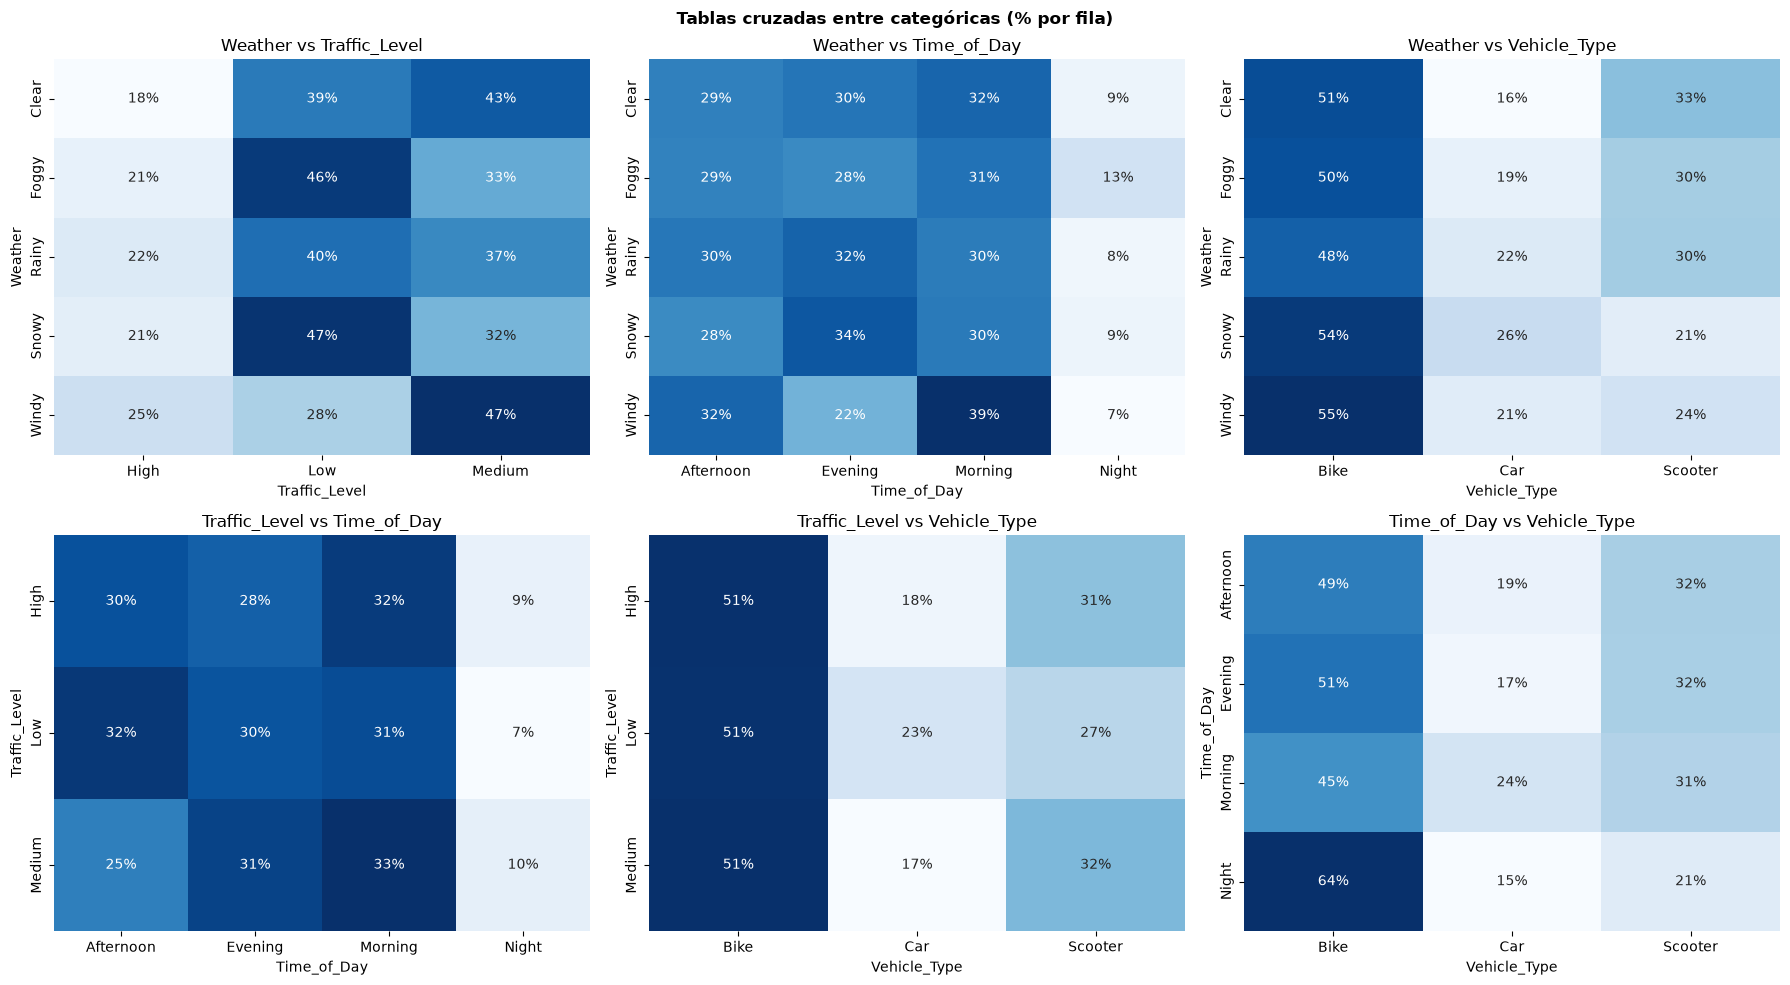

In [35]:
# Tablas cruzadas entre categóricas (proporción por fila)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (a, b) in zip(axes.flat, combinations(categoricas, 2)):
    ct = pd.crosstab(df[a], df[b], normalize="index")
    sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{a} vs {b}")
plt.suptitle("Tablas cruzadas entre categóricas (% por fila)", fontweight="bold")
plt.tight_layout()
plt.show()

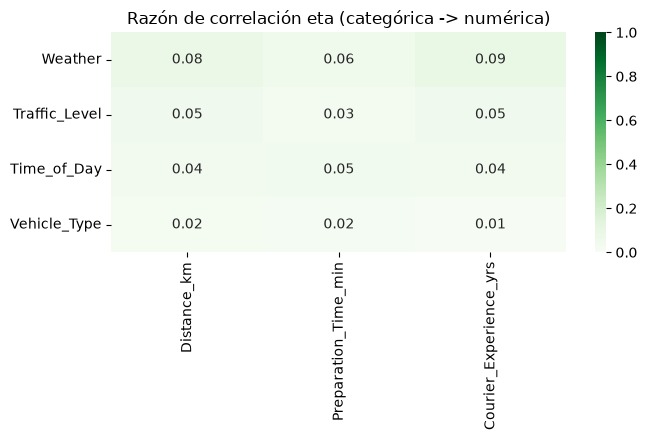

In [36]:
# Numéricas (predictoras) vs. categóricas: eta
eta_mat = pd.DataFrame(index=categoricas, columns=numericas, dtype=float)
for c in categoricas:
    for n in numericas:
        eta_mat.loc[c, n] = eta(df[c], df[n])

plt.figure(figsize=(7, 4.5))
sns.heatmap(eta_mat, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1)
plt.title("Razón de correlación eta (categórica -> numérica)")
plt.tight_layout()
plt.show()

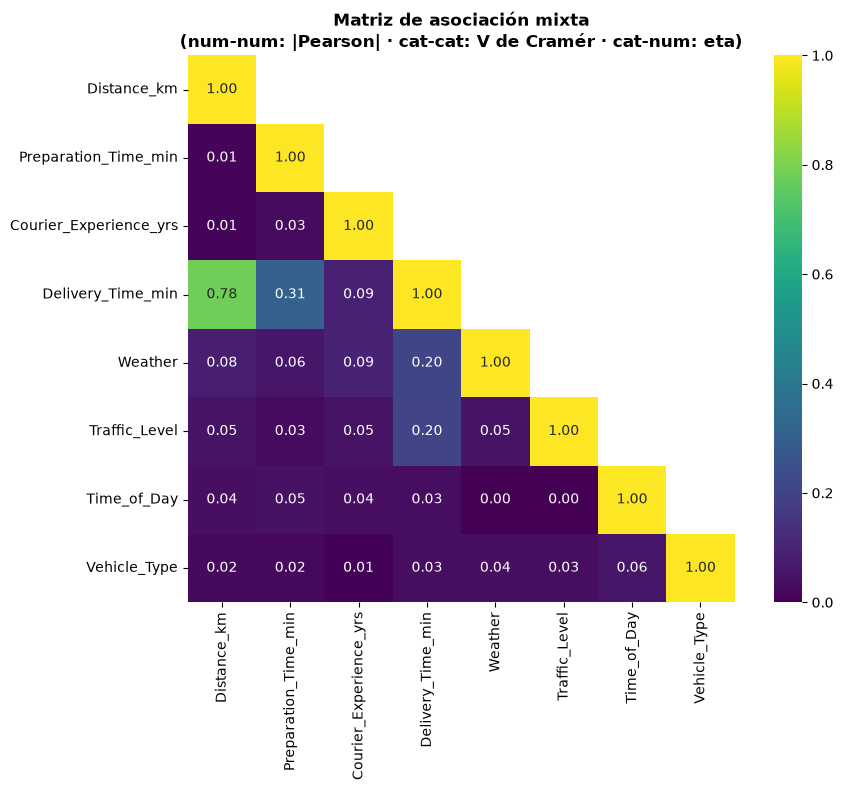


=== Ranking de asociación con Delivery_Time ===
Distance_km               0.781
Preparation_Time_min      0.307
Weather                   0.204
Traffic_Level             0.200
Courier_Experience_yrs    0.090
Vehicle_Type              0.034
Time_of_Day               0.034
Name: Delivery_Time_min, dtype: float64


In [38]:
# Resumen, todas las variables: matriz de asociación mixta
todas = num_all + categoricas
mixta = pd.DataFrame(np.eye(len(todas)), index=todas, columns=todas)

for a, b in combinations(todas, 2):
    if a in num_all and b in num_all:
        val = abs(df[[a, b]].corr().iloc[0, 1])      # |Pearson|
    elif a in categoricas and b in categoricas:
        d = df[[a, b]].dropna()
        val = cramers_v(d[a], d[b])                  # V de Cramér
    else:
        cat, num = (a, b) if a in categoricas else (b, a)
        val = eta(df[cat], df[num])                  # eta
    mixta.loc[a, b] = mixta.loc[b, a] = val

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(mixta, dtype=bool), k=1)
sns.heatmap(mixta, mask=mask, annot=True, fmt=".2f", cmap="viridis",
            vmin=0, vmax=1, square=True)
plt.title("Matriz de asociación mixta\n(num-num: |Pearson| · cat-cat: V de Cramér · cat-num: eta)",
          fontweight="bold")
plt.tight_layout()
plt.show()

print("\n=== Ranking de asociación con Delivery_Time ===")
print(mixta[target].drop(target).sort_values(ascending=False).round(3))

### Dispersión de Delivery_Time coloreada por variables categóricas

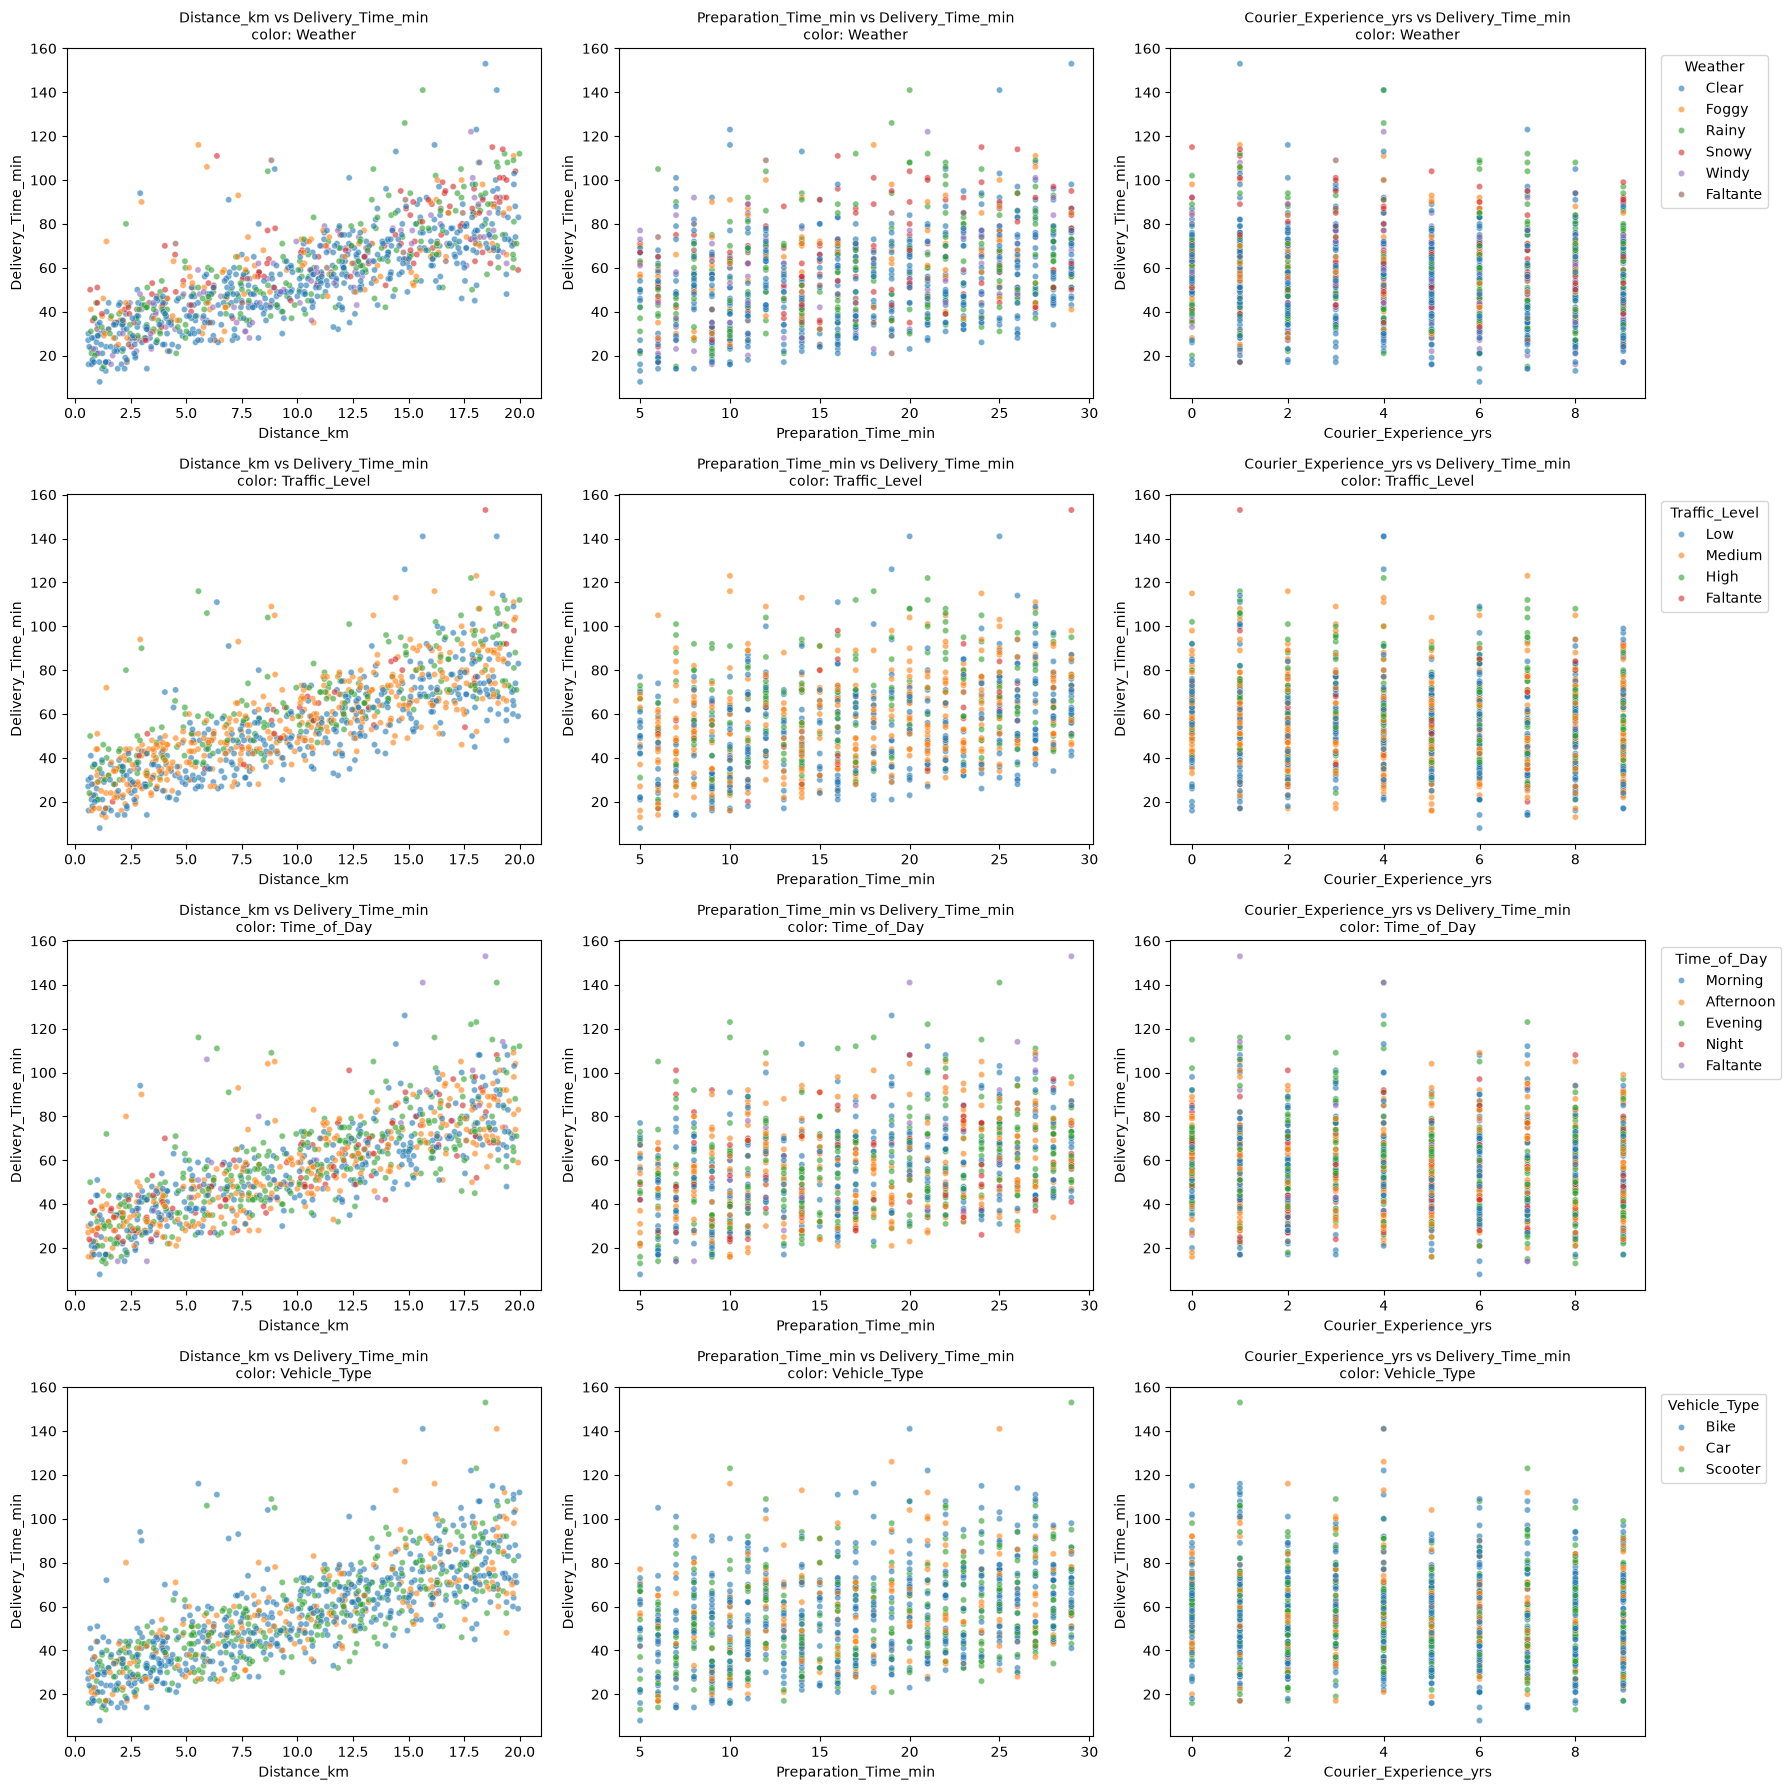

In [39]:
orden_cat = {
    "Traffic_Level": ["Low", "Medium", "High"],
    "Time_of_Day": ["Morning", "Afternoon", "Evening", "Night"],
}

# Copia con los faltantes de las categóricas como categoría propia
dfp = df.copy()
for c in categoricas:
    dfp[c] = dfp[c].fillna("Faltante")

def orden_de(col):
    base = [o for o in orden_cat.get(col, []) if o in dfp[col].unique()]
    resto = sorted(v for v in dfp[col].unique() if v not in base and v != "Faltante")
    return base + resto + (["Faltante"] if "Faltante" in dfp[col].unique() else [])

# 1. Cuadrícula: filas = categóricas (color), columnas = numéricas (eje X)
fig, axes = plt.subplots(len(categoricas), len(numericas),
                         figsize=(6 * len(numericas), 4.5 * len(categoricas)))

for i, cat in enumerate(categoricas):
    orden = orden_de(cat)
    for j, num in enumerate(numericas):
        ax = axes[i, j]
        sns.scatterplot(data=dfp, x=num, y=target, hue=cat, hue_order=orden,
                        alpha=0.6, s=20, ax=ax, legend=(j == len(numericas) - 1))
        ax.set_title(f"{num} vs {target}\ncolor: {cat}", fontsize=10)
        if j == len(numericas) - 1:
            ax.legend(title=cat, bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()